In [1]:
#Get month wise EAD

In [2]:
import pandas as pd
import numpy as np

# Load the exposure data sheet
file_path = "default_recovery_dataset.xlsx"
df = pd.read_excel(file_path, sheet_name="Exposure_Data")

# Ensure Default_Date is a datetime field
df['Default_Date'] = pd.to_datetime(df['Default_Date'])

# Create a Year-Month column
df['Month'] = df['Default_Date'].dt.to_period('M').dt.to_timestamp()

# Group by Month and sum EAD
monthly_ead = df.groupby('Month')['EAD'].sum().reset_index()

# Create complete month range from Jan 2013 to Dec 2022
all_months = pd.date_range(start="2013-01-01", end="2022-12-01", freq='MS')
all_months_df = pd.DataFrame({'Month': all_months})

# Merge to ensure all months appear (missing months = 0 EAD)
monthly_ead_final = all_months_df.merge(monthly_ead, on="Month", how="left").fillna(0)

# (Optional) rename columns
monthly_ead_final = monthly_ead_final.rename(columns={"EAD": "Total_Monthly_EAD"})

print(monthly_ead_final)


         Month  Total_Monthly_EAD
0   2013-01-01            3747140
1   2013-02-01            4920347
2   2013-03-01            4711716
3   2013-04-01            3659682
4   2013-05-01            5259799
..         ...                ...
115 2022-08-01            5098088
116 2022-09-01            3936772
117 2022-10-01            3000945
118 2022-11-01            4608953
119 2022-12-01            4544055

[120 rows x 2 columns]


In [3]:
#Get months from 31-12-2022

In [4]:
import pandas as pd

# Load the exposure data sheet
file_path = "default_recovery_dataset.xlsx"
df = pd.read_excel(file_path, sheet_name="Exposure_Data")

# Ensure Default_Date is datetime
df['Default_Date'] = pd.to_datetime(df['Default_Date'])

# Create a fixed end date
end_date = pd.to_datetime("2022-12-31")

# Compute month difference
df['Months_From_End'] = ((end_date.year - df['Default_Date'].dt.year) * 12 +
                         (end_date.month - df['Default_Date'].dt.month)).astype(int)

# Create table with Borrower and Months_From_End
borrower_months_table = df[['Borrower_ID', 'Default_Date', 'Months_From_End']]

print(borrower_months_table)


      Borrower_ID Default_Date  Months_From_End
0     BORR_000001   2013-01-01              119
1     BORR_000002   2013-01-02              119
2     BORR_000003   2013-01-04              119
3     BORR_000004   2013-01-06              119
4     BORR_000005   2013-01-10              119
...           ...          ...              ...
1995  BORR_001996   2022-12-26                0
1996  BORR_001997   2022-12-28                0
1997  BORR_001998   2022-12-29                0
1998  BORR_001999   2022-12-29                0
1999  BORR_002000   2022-12-31                0

[2000 rows x 3 columns]


In [5]:
#Create Vintage table which includes date of default as row headers and Development months(Months since default) as column headers

In [6]:
import pandas as pd

# Valuation date
valuation_date = pd.to_datetime("2027-08-01")

# Default months (rows)
default_months = pd.date_range(
    start="2013-01-01",
    end="2022-12-01",
    freq="MS"
)

default_months_fmt = default_months.strftime("%m-%y")

# Max development months (earliest default → valuation date)
earliest_default = default_months.min()

num_months = (
    (valuation_date.year - earliest_default.year) * 12 +
    (valuation_date.month - earliest_default.month)
)

# Development month columns
columns = [f"Month_{i}" for i in range(1, num_months + 1)]

# CREATE TABLE (this is what Code 3 needs)
table = pd.DataFrame(
    index=default_months_fmt,
    columns=columns
)


In [7]:
#Fill NaNs with Yes and No depending on whether Development month >= default month where Yes if it is true and No if it is <default month

In [8]:

# Assume your matrix is called `table`
# Index: "MM-YY"
# Columns: Month_1, Month_2, ..., Month_N

# -----------------------------
# 1. Set current date
# -----------------------------
current_date = pd.to_datetime("2027-08-01")

# -----------------------------
# 2. Convert default month index to datetime
# -----------------------------
default_dates = pd.to_datetime(table.index, format="%m-%y")

# -----------------------------
# 3. Compute months since default
# -----------------------------
months_since_default = (
    (current_date.year - default_dates.year) * 12 +
    (current_date.month - default_dates.month)
)

# -----------------------------
# 4. Replace NaNs with Yes / No
# -----------------------------
for col in table.columns:
    dev_month = int(col.split("_")[1])  # Month_1 → 1

    table[col] = np.where(
        months_since_default >= dev_month,
        "Yes",
        "No"
    )

print(table.head())


      Month_1 Month_2 Month_3 Month_4 Month_5 Month_6 Month_7 Month_8 Month_9  \
01-13     Yes     Yes     Yes     Yes     Yes     Yes     Yes     Yes     Yes   
02-13     Yes     Yes     Yes     Yes     Yes     Yes     Yes     Yes     Yes   
03-13     Yes     Yes     Yes     Yes     Yes     Yes     Yes     Yes     Yes   
04-13     Yes     Yes     Yes     Yes     Yes     Yes     Yes     Yes     Yes   
05-13     Yes     Yes     Yes     Yes     Yes     Yes     Yes     Yes     Yes   

      Month_10  ... Month_166 Month_167 Month_168 Month_169 Month_170  \
01-13      Yes  ...       Yes       Yes       Yes       Yes       Yes   
02-13      Yes  ...       Yes       Yes       Yes       Yes       Yes   
03-13      Yes  ...       Yes       Yes       Yes       Yes       Yes   
04-13      Yes  ...       Yes       Yes       Yes       Yes       Yes   
05-13      Yes  ...       Yes       Yes       Yes       Yes       Yes   

      Month_171 Month_172 Month_173 Month_174 Month_175  
01-13       Yes 

In [9]:
#Load Expoure_Data and Recovery_Data

In [10]:
import pandas as pd
import numpy as np

exposure_df = pd.read_excel(
    "default_recovery_dataset.xlsx",
    sheet_name="Exposure_Data"
)

recovery_df = pd.read_excel(
    "default_recovery_dataset.xlsx",
    sheet_name="Recovery_Data"
)

exposure_df['Default_Date'] = pd.to_datetime(exposure_df['Default_Date'])
recovery_df['Recovery_Date'] = pd.to_datetime(recovery_df['Recovery_Date'])


In [11]:
#Find crysstallissation period by finding cumulative recovery % 

In [12]:
#Step 1- Load both sheets

In [13]:
exposure_df = pd.read_excel("default_recovery_dataset.xlsx", sheet_name="Exposure_Data")
recovery_df = pd.read_excel("default_recovery_dataset.xlsx", sheet_name="Recovery_Data")

# Ensure datetime
exposure_df['Default_Date'] = pd.to_datetime(exposure_df['Default_Date'])
recovery_df['Recovery_Date'] = pd.to_datetime(recovery_df['Recovery_Date'])


In [14]:
#Step 2 — Merge Default_Date & EAD to recovery_df

In [15]:
recovery_df = recovery_df.merge(
    exposure_df[['Borrower_ID', 'Default_Date', 'EAD']],
    on='Borrower_ID',
    how='left'
)


In [16]:
#Step 3 — Map to Default_Month and Development Month


In [17]:
# Default month in MM-YY format
recovery_df['Default_Month'] = recovery_df['Default_Date'].dt.to_period('M').dt.strftime("%m-%y")

# Development month based on Days_Since_Default
recovery_df['Dev_Month'] = (recovery_df['Days_Since_Default'] // 30 + 1).astype(int)


In [18]:
# Keep the correct EAD from exposure_df
recovery_df['EAD'] = recovery_df['EAD_y']

# Drop unnecessary duplicate columns
recovery_df.drop(columns=['EAD_x', 'EAD_y'], inplace=True)


In [19]:
#Step 4 — Compute cumulative recovery % per borrower per dev month

In [20]:
recovery_df['Cumulative_Recovery_Pct'] = (recovery_df['Cumulative_Recovery'] / recovery_df['EAD']) * 100


In [21]:
recovery_df[['Borrower_ID','Default_Date','EAD','Cumulative_Recovery','Cumulative_Recovery_Pct']].head()


,Borrower_ID,Default_Date,EAD,Cumulative_Recovery,Cumulative_Recovery_Pct
0,BORR_000001,2013-01-01,190397,16573,8.704444
1,BORR_000001,2013-01-01,190397,27441,14.412517
2,BORR_000001,2013-01-01,190397,37033,19.450412
3,BORR_000002,2013-01-02,475604,9232,1.941111
4,BORR_000002,2013-01-02,475604,24762,5.206432


In [22]:
#Step 1 — Ensure cumulative recovery % is ready


In [23]:
# recovery_df must have: Borrower_ID, Default_Month, Dev_Month, Cumulative_Recovery_Pct
# Use existing Dev_Month if already present
# Ensure Default_Month is in MM-YY format to match table index
recovery_df['Default_Month'] = recovery_df['Default_Date'].dt.to_period('M').dt.strftime("%m-%y")


In [24]:
#Step 2 — Aggregate cumulative recovery % for each Default_Month × Dev_Month

In [25]:
agg_df = (
    recovery_df.groupby(['Default_Month', 'Dev_Month'])
    .agg({'Cumulative_Recovery_Pct':'mean'})  # average % across borrowers
    .reset_index()
)


In [26]:
#Step 3 — Pivot to match table format

In [27]:
vintage_matrix = agg_df.pivot(
    index='Default_Month',
    columns='Dev_Month',
    values='Cumulative_Recovery_Pct'
)

# Rename columns to match your "Month_1", "Month_2", ... headers
vintage_matrix.columns = [f"Month_{int(c)}" for c in vintage_matrix.columns]

# Align with your existing Yes/No table
vintage_matrix = vintage_matrix.reindex(index=table.index, columns=table.columns)


In [28]:
#Step 4 — Replace "Yes" with cumulative recovery %, keep "No"

In [29]:
final_matrix = vintage_matrix.where(table == "Yes", table)


In [30]:
# Print the full final matrix (may be large)
print(final_matrix)

# Or print the first few rows to check
print(final_matrix.head())


       Month_1  Month_2  Month_3    Month_4    Month_5    Month_6    Month_7  \
01-13      NaN      NaN      NaN        NaN  23.321325   8.704444  36.029749   
02-13      NaN      NaN      NaN  14.118895  32.700803  23.177790  23.331479   
03-13      NaN      NaN      NaN  23.659647  11.188117  34.103797  15.653706   
04-13      NaN      NaN      NaN  24.886032  36.543923  29.826990  62.080977   
05-13      NaN      NaN      NaN  55.482619  11.112016  12.055868  43.229939   
...        ...      ...      ...        ...        ...        ...        ...   
08-22      NaN      NaN      NaN   5.936885  16.787560  51.820483  21.753089   
09-22      NaN      NaN      NaN        NaN  30.997364   7.998117        NaN   
10-22      NaN      NaN      NaN        NaN   8.203176        NaN  15.559735   
11-22      NaN      NaN      NaN   1.997720  35.435438        NaN  29.940795   
12-22      NaN      NaN      NaN  24.475478  17.886594  36.813634  51.509012   

         Month_8    Month_9   Month_10 

In [31]:
#Compute average of Numeric value for each development month ignoring NaNs and No

In [32]:
import pandas as pd
import numpy as np

# Assuming your vintage matrix is called final_matrix
# Select only Month_1 to Month_175 columns
month_cols = [col for col in final_matrix.columns if col.startswith('Month_')]

# Compute column-wise averages ignoring NaN and non-numeric values
month_avg = {}

for col in month_cols:
    # Convert the column to numeric, errors='coerce' will turn 'No' and other non-numeric into NaN
    numeric_values = pd.to_numeric(final_matrix[col], errors='coerce')
    
    # Compute mean ignoring NaNs
    month_avg[col] = numeric_values.mean()

# Convert to DataFrame for easier display
month_avg_df = pd.DataFrame(list(month_avg.items()), columns=['Month', 'Average_Cumulative_Recovery'])
print(month_avg_df)


         Month  Average_Cumulative_Recovery
0      Month_1                          NaN
1      Month_2                          NaN
2      Month_3                          NaN
3      Month_4                    22.848519
4      Month_5                    22.669601
..         ...                          ...
170  Month_171                          NaN
171  Month_172                          NaN
172  Month_173                          NaN
173  Month_174                          NaN
174  Month_175                          NaN

[175 rows x 2 columns]


In [33]:
#Calculation of crystallisation period where rrecovery touches 70%

In [34]:
# Find first development month where average recovery >= 70%
threshold = 70

# Filter months where avg >= threshold
months_above_threshold = month_avg_df[month_avg_df['Average_Cumulative_Recovery'] >= threshold]

if not months_above_threshold.empty:
    crystallization_month = months_above_threshold.iloc[0]['Month']
    print(f"Development month where average cumulative recovery reaches {threshold}%: {crystallization_month}")
else:
    print(f"No development month reaches {threshold}% average cumulative recovery.")


No development month reaches 70% average cumulative recovery.


In [35]:
#Find maximum of average cumulative recovery

In [36]:
max_avg = month_avg_df['Average_Cumulative_Recovery'].max()
max_month = month_avg_df.loc[month_avg_df['Average_Cumulative_Recovery'].idxmax(), 'Month']
print(f"Maximum average cumulative recovery: {max_avg:.2f}% at {max_month}")


Maximum average cumulative recovery: 65.99% at Month_59


In [80]:
#Print month where 95% of peak recovery is happening

In [82]:
# -----------------------------
# 1. Compute 95% of peak recovery
# -----------------------------
peak_recovery = month_avg_df['Average_Cumulative_Recovery'].max()
threshold_95 = 0.95 * peak_recovery

print(f"Peak average recovery: {peak_recovery:.2f}%")
print(f"95% of peak recovery: {threshold_95:.2f}%")

# -----------------------------
# 2. Find first month reaching 95% of peak
# -----------------------------
crystallisation_row = month_avg_df[
    month_avg_df['Average_Cumulative_Recovery'] >= threshold_95
].iloc[0]

crystallisation_month = crystallisation_row['Month']
crystallisation_value = crystallisation_row['Average_Cumulative_Recovery']

print(
    f"Crystallisation period (95% of peak): "
    f"{crystallisation_month} "
    f"with average recovery {crystallisation_value:.2f}%"
)


Peak average recovery: 65.99%
95% of peak recovery: 62.69%
Crystallisation period (95% of peak): Month_59 with average recovery 65.99%


In [84]:
#Plot recovery curve

In [88]:
#Prepare data for plotting
import matplotlib.pyplot as plt

# Ensure numeric month ordering
plot_df = month_avg_df.copy()
plot_df['Month_Num'] = plot_df['Month'].str.extract(r'(\d+)').astype(int)
plot_df = plot_df.sort_values('Month_Num')


In [90]:
#Define crystallisation threshold and month
threshold = 62.69
crystallisation_month_num = 59


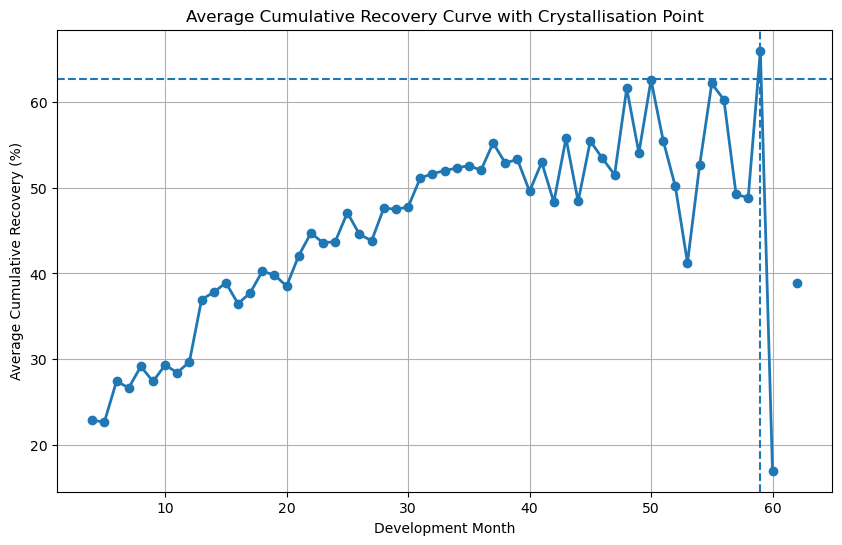

In [92]:
#Plot the recovery curve (correct way)
plt.figure(figsize=(10, 6))

# Recovery curve
plt.plot(
    plot_df['Month_Num'],
    plot_df['Average_Cumulative_Recovery'],
    marker='o',
    linewidth=2
)

# Horizontal line: 95% of peak
plt.axhline(
    y=threshold,
    linestyle='--'
)

# Vertical line: crystallisation month
plt.axvline(
    x=crystallisation_month_num,
    linestyle='--'
)

# Labels and title
plt.xlabel('Development Month')
plt.ylabel('Average Cumulative Recovery (%)')
plt.title('Average Cumulative Recovery Curve with Crystallisation Point')

# Grid for readability
plt.grid(True)

plt.show()


In [94]:
#Freeze / truncate the recovery curve at the crystallisation period (Month_59)

In [96]:
crystal_month = 59

truncated_df = plot_df.copy()

# Get recovery at crystallisation
crystal_recovery = truncated_df.loc[
    truncated_df['Month_Num'] == crystal_month,
    'Average_Cumulative_Recovery'
].values[0]

# Freeze beyond crystallisation
truncated_df.loc[
    truncated_df['Month_Num'] > crystal_month,
    'Average_Cumulative_Recovery'
] = crystal_recovery


In [98]:
#Discount cumulative recoveries to bring them to month of default

In [102]:
#Step 1- Convert Cumulative to Incremental recoveries

In [104]:
discount_rate_annual = 0.15

disc_df = truncated_df.copy()

# Sort by development month
disc_df = disc_df.sort_values('Month_Num')

# Convert cumulative % to incremental %
disc_df['Incremental_Recovery_Pct'] = (
    disc_df['Average_Cumulative_Recovery'].diff().fillna(
        disc_df['Average_Cumulative_Recovery']
    )
)


In [106]:
#STEP 2 — Create monthly discount factors (15% p.a.)

In [108]:
disc_df['Discount_Factor'] = (
    1 / (1 + discount_rate_annual) ** (disc_df['Month_Num'] / 12)
)


In [110]:
#STEP 3 — Discount incremental recoveries to time of default

In [112]:
disc_df['Discounted_Incremental_Recovery_Pct'] = (
    disc_df['Incremental_Recovery_Pct'] * disc_df['Discount_Factor']
)


In [114]:
#STEP 4 — Compute total discounted recovery and LGD

In [116]:
discounted_recovery_pct = disc_df[
    'Discounted_Incremental_Recovery_Pct'
].sum()

print(f"Discounted cumulative recovery (% of EAD): {discounted_recovery_pct:.2f}%")


Discounted cumulative recovery (% of EAD): 52.86%


In [118]:
#LGD (time-of-default basis)

In [120]:
LGD = 1 - discounted_recovery_pct / 100
print(f"LGD (discounted at 15% p.a.): {LGD:.4f}")


LGD (discounted at 15% p.a.): 0.4714


In [126]:
#Estimate rho(correlation) between PD & LGD using historical data

In [128]:
import pandas as pd
import statsmodels.api as sm
import numpy as np

# Example: historical PD and LGD
# Replace this with your own portfolio-level data
data = {
    'PD': [0.012, 0.05, 0.045, 0.011, 0.013, 0.009, 0.014],
    'LGD': [0.35, 0.67, 0.38, 0.53, 0.68, 0.32, 0.37]
}
df = pd.DataFrame(data)

# Regression: LGD ~ PD
X = sm.add_constant(df['PD'])  # adds intercept term
y = df['LGD']

model = sm.OLS(y, X).fit()
print(model.summary())

# Extract beta coefficient
beta = model.params['PD']

# Estimate rho
rho_est = beta * df['PD'].std() / df['LGD'].std()
print(f"Estimated correlation (rho) between PD and LGD: {rho_est:.3f}")


                            OLS Regression Results                            
Dep. Variable:                    LGD   R-squared:                       0.092
Model:                            OLS   Adj. R-squared:                 -0.089
Method:                 Least Squares   F-statistic:                    0.5077
Date:                Thu, 18 Dec 2025   Prob (F-statistic):              0.508
Time:                        22:50:54   Log-Likelihood:                 4.0315
No. Observations:                   7   AIC:                            -4.063
Df Residuals:                       5   BIC:                            -4.171
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.4127      0.102      4.031      0.0

C:\Users\swara\anaconda3\Lib\site-packages\statsmodels\stats\stattools.py:74: ValueWarning: omni_normtest is not valid with less than 8 observations; 7 samples were given.
  warn("omni_normtest is not valid with less than 8 observations; %i "


In [130]:
#Compute PIT LGD using Jacob Frye formula


In [134]:
from scipy.stats import norm

# Inputs
TTC_LGD = 0.34
TTC_PD = 0.01
PIT_PD = 0.015
rho = 0.304

# Expected Loss %
EL = TTC_LGD * TTC_PD

# Compute K
K = (norm.ppf(TTC_PD) - norm.ppf(EL)) / np.sqrt(1 - rho)

# Compute PIT LGD
PIT_LGD = norm.cdf(norm.ppf(PIT_PD) - K) / PIT_PD

print(f"PIT LGD (Jacob Frye formula): {PIT_LGD:.4f}")


PIT LGD (Jacob Frye formula): 0.2882
